# Hwang et al. 2022 — PDAC
## 02 · Cell-state manifold & trajectory

Gate 1 passed (one continuous, sample-integrated manifold). Here I settle the **topology** and fit
the trajectory that 03 reads. Two questions: does the malignant manifold **branch** — a Gast/pSom
co-expression hub diverging into two cross-repressing arms (scFates `tree`) — or is it
**non-branching** (scFates `curve`); and, if non-branching, what is the developmental ordering
(root by the signatures' developmental order — Gast/pSom is the origin, neural-crest is late;
03_eval fork 3)?

The topology probes below (PPT fork count vs node scale; co-expression-hub test) show **no discrete
bifurcation and no Gast/pSom co-expression hub**, so the manifold is fit with a **principal curve**
on the joint embedding — no re-embedding (re-embedding a compartment fabricates folds; 03_eval fork
4). Deliverables: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, warnings, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat= os.path.join(pth_data, 'features', 'biomart')
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
print('loaded processed.h5ad:', adata.shape)

loaded processed.h5ad: (63997, 19444)


### Score developmental modules (needed to root the trajectory)
Gast / pSom / Crest scored against the shared **union** control pool. Graph-smoothed copies
(kNN-connectivity averaging) are computed as an analysis aid for reading geography; the raw scores
are the honest per-cell readout carried into 03.

In [ ]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.asarray(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:, j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present
raw module means: {'Gast': -0.0044, 'pSom': -0.002, 'Crest': 0.0025}


### Topology probe 1 — a PPT tree over-fits the continuous cloud (no clean bifurcation)
If the manifold branched, a PPT `tree` would recover a small, stable number of biologically
meaningful forks. Instead the fork count **grows with node count** at fixed regularisation — the
signature of fitting a filled continuous mass, not a discrete Y (02_train C3: the "clean
bifurcation" assumption fails). → non-branching.

In [ ]:
adata.obsm['X_rep20'] = adata.obsm['X_pca_harmony'][:, :20]
def treediag(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B > 0).sum(0)
    return int((deg == 1).sum()), int((deg >= 3).sum())
print('PPT tree tips/forks across node counts:')
for Nodes in [50, 100, 200]:
    ad2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad2, Nodes=Nodes, use_rep='X_umap', method='ppt',
                    ppt_sigma=0.5, ppt_lambda=2000, seed=SEED, plot=False)
    t, f = treediag(ad2); print(f'  Nodes={Nodes}: {t} tips, {f} forks')
print('-> forks scale with node count: no discrete branch.')

PPT tree tips/forks across node counts:
  Nodes=50: 7 tips, 5 forks
  Nodes=100: 10 tips, 8 forks
  Nodes=200: 11 tips, 9 forks
-> forks scale with node count: no discrete branch.


### Topology probe 2 — no Gast/pSom co-expression hub
A Puram-type branch needs a **convergence zone** where Gast and pSom co-express before splitting.
Testing the manifold interior (inner 50% by UMAP radius): the fraction of cells co-high for both
modules is compared to the independence expectation. Enrichment < 1 means the two programmes are
mutually exclusive (no co-expression hub) rather than converging. Combined with probe 1, the
topology is a **principal curve**.

In [ ]:
from sklearn.neighbors import NearestNeighbors
um = adata.obsm['X_umap']; ctr = um.mean(0); rad = np.linalg.norm(um - ctr, axis=1)
hub = rad <= np.quantile(rad, 0.5)
gz = (adata.obs['Gast_sm'] - adata.obs['Gast_sm'].mean())/adata.obs['Gast_sm'].std()
pz = (adata.obs['pSom_sm'] - adata.obs['pSom_sm'].mean())/adata.obs['pSom_sm'].std()
joint = ((gz[hub] > 0.5) & (pz[hub] > 0.5)).mean()
exp   = (gz[hub] > 0.5).mean() * (pz[hub] > 0.5).mean()
print(f'interior Gast&pSom co-high enrichment = {joint/exp:.2f}  (>1 co-expression hub; <1 mutually exclusive)')

interior Gast&pSom co-high enrichment = 0.75  (>1 co-expression hub; <1 mutually exclusive)


### Fit the principal curve (ElPiGraph, non-branching)
On the joint UMAP embedding (no re-embedding). Curve parameters match the passing same-tissue PDAC
runs (Peng/Steele/Moncada): `Nodes=20, epg_lambda=0.3, epg_mu=100`.

In [ ]:
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100, seed=SEED, plot=False)
B = np.asarray(adata.uns['graph']['B']); deg = (B > 0).sum(0)
print(f'principal curve: {B.shape[0]} nodes, {int((deg==1).sum())} tips, {int((deg>=3).sum())} forks')

inferring a principal curve --> parameters used 
    20 principal points, mu = 100, lambda = 0.3
    finished (0:00:07) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
principal curve: 20 nodes, 2 tips, 0 forks


### Root by developmental order (Gast/pSom origin; Crest is late)
The two curve tips are scored by their developmental modules. Neural crest is a **late** programme
(03_eval fork 3), so the root is the tip with higher Gast+pSom and lower Crest. Pseudotime then
runs from that origin.

In [ ]:
tips = np.where(deg == 1)[0]
R = adata.obsm['X_R']  # cell x node soft assignment
def tip_scores(tip):
    w = R[:, tip]
    return (np.average(adata.obs['Gast'], weights=w),
            np.average(adata.obs['pSom'], weights=w),
            np.average(adata.obs['Crest'], weights=w))
sc_tips = {int(t): tip_scores(t) for t in tips}
for t,(gg,pp,cc) in sc_tips.items():
    print(f'  tip node {t}: Gast {gg:+.4f}  pSom {pp:+.4f}  Crest {cc:+.4f}  (Gast+pSom-Crest {gg+pp-cc:+.4f})')
root = max(sc_tips, key=lambda t: sc_tips[t][0] + sc_tips[t][1] - sc_tips[t][2])
print('root = tip node', root, '(highest Gast+pSom-Crest = developmental origin; Gast/pSom is the root, Crest is late)')
scf.tl.root(adata, int(root))
scf.tl.pseudotime(adata, n_map=1, seed=SEED)

  tip node 0: Gast -0.0054  pSom -0.0015  Crest +0.0053  (Gast+pSom-Crest -0.0121)
  tip node 2: Gast -0.0170  pSom +0.0020  Crest +0.0029  (Gast+pSom-Crest -0.0178)
root = tip node 0 (highest Gast+pSom-Crest = developmental origin; Gast/pSom is the root, Crest is late)
node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:57) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


### Developmental ordering along pseudotime
Spearman correlation of each module's smoothed score with pseudotime. A **reproducing** dataset
orders Gast/pSom early (root) and Crest **late** (terminal, positive rho). The modules are only
weakly structured along the axis here, and — as the printout shows — Crest does **not** rise toward
the terminus (its rho is negative, i.e. Crest is not a late programme on this manifold). This is the
first quantitative sign that the embryonic ordering does not reproduce; the **module geography** in
03 makes the Gate-2 call. Cell cycle is not a confound (|rho| <= 0.04 for every module).

In [ ]:
t = adata.obs['t'].values
for lab in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[lab].values)
    print(f'  {lab:9s} vs pseudotime: rho = {rho:+.3f}')
for lab in ['Gast','pSom','Crest']:
    cyc_cols = [c for c in ['g1s_score','g2m_score'] if c in adata.obs.columns]
    if cyc_cols:
        cyc = np.maximum.reduce([pd.to_numeric(adata.obs[c],errors='coerce').fillna(0).values for c in cyc_cols])
        rho,_ = spearmanr(cyc, adata.obs[lab].values)
        print(f'  {lab} vs cycling score: rho = {rho:+.2f}')

  Gast_sm   vs pseudotime: rho = -0.245
  pSom_sm   vs pseudotime: rho = +0.263
  Crest_sm  vs pseudotime: rho = -0.362
  Gast vs cycling score: rho = -0.02
  pSom vs cycling score: rho = -0.04
  Crest vs cycling score: rho = +0.03


### Rename milestones and save `manifold.h5ad`

In [ ]:
# label the two milestones by mean pseudotime: earliest = Origin, latest = Terminal
mil = adata.obs['milestones'].astype(str)
mt = {m: adata.obs.loc[mil == m, 't'].mean() for m in mil.unique()}
order = sorted(mt, key=lambda m: mt[m])
mnames = {order[0]: 'Origin (root)', order[-1]: 'Terminal'}
scf.tl.rename_milestones(adata, new=mnames)
print('milestones (by pseudotime):', {k: round(v,2) for k,v in mt.items()})
print('milestone labels:', dict(adata.obs['milestones'].value_counts()))
# drop the ElPiGraph raw dict (ragged 'Edges' list is not h5ad-serializable; curve nodes live in uns['graph'])
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

milestones (by pseudotime): {'2': np.float64(8.86), '0': np.float64(2.42)}
milestone labels: {'Origin (root)': np.int64(34257), 'Terminal': np.int64(29740)}
saved manifold.h5ad (63997, 19444)


### Figure — `manifold.pdf`
Pseudotime on the manifold **with the principal-curve edges drawn** (a curve must be rendered with
its edges so folds are visible — 04_test / Chen attempt 6). House `(3.5,1.5)` linear-trajectory
aspect, consistent inverted orientation, external colorbar.

saved manifold.pdf
saved colorbars/t_colorbar.pdf


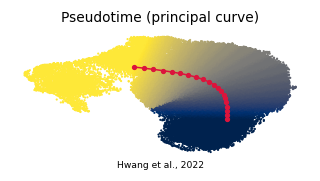

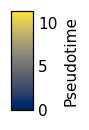

In [ ]:
os.makedirs(pth_fig, exist_ok=True)
xy = adata.obsm['X_umap']; F = np.asarray(adata.uns['graph']['F'])  # 2 x nodes
fig, ax = plt.subplots(1, 1, figsize=(3.5, 1.5))
sctr = ax.scatter(xy[:,0], xy[:,1], c=adata.obs['t'], cmap='cividis', s=2, linewidths=0, rasterized=True)
ii, jj = np.where(np.triu(B > 0))
for i,j in zip(ii, jj):
    ax.plot([F[0,i],F[0,j]], [F[1,i],F[1,j]], '-', color='crimson', lw=1.0, zorder=3)
ax.scatter(F[0], F[1], s=6, color='crimson', zorder=4)
ax.invert_yaxis(); ax.invert_xaxis(); ax.axis('off')
ax.set_title('Pseudotime (principal curve)', size=9)
ax.text(.5, -.08, 'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight', dpi=200)
print('saved manifold.pdf')
# external colorbar
figc = plt.figure(figsize=(.66,1)); cax = figc.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(sctr, cax=cax); cb.ax.tick_params(size=0); cb.set_label('Pseudotime')
os.makedirs(os.path.join(pth_fig,'colorbars'), exist_ok=True)
figc.savefig(os.path.join(pth_fig,'colorbars','t_colorbar.pdf'), bbox_inches='tight')
print('saved colorbars/t_colorbar.pdf')